# День 3. Baseline: TF-IDF + Logistic Regression

Baseline строго по README: TF-IDF (5000 признаков, 1-2 граммы) + LogisticRegression, разбиение 80/20 со стратификацией. Пайплайн беру из шаблона `train_model.py`.

In [7]:
import sys
sys.path.insert(0, "../src")

import os
import json
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, f1_score, accuracy_score, ConfusionMatrixDisplay

from finnews_sentiment.models.train_model import build_baseline_pipeline
from finnews_sentiment.features.preprocess import LABEL_NAMES

os.makedirs("../models", exist_ok=True)
os.makedirs("../results", exist_ok=True)
os.makedirs("../reports", exist_ok=True)

In [8]:
df = pd.read_csv("data/financial_clean.csv").dropna(subset=["text_clean"])
print(df.shape)
print(df["sentiment"].value_counts())

(4803, 9)
sentiment
neutral     2610
positive    1850
negative     343
Name: count, dtype: int64


Разбиение train/test. Эти же параметры (test_size=0.2, random_state=42, stratify) использую в днях 4 и 5, чтобы все модели сравнивались на одном и том же test.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    df["text_clean"], df["label"], test_size=0.2, random_state=42, stratify=df["label"]
)
print(len(X_train), len(X_test))
print(y_test.value_counts())

3842 961
label
1    522
2    370
0     69
Name: count, dtype: int64


In [10]:
model = build_baseline_pipeline()   # tfidf(max_features=5000, ngram_range=(1, 2)) + LogisticRegression(max_iter=200)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

/Users/mak/Desktop/WORKPLACE/ML_валютная удаленка/Проекты/transformers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


In [11]:
print(classification_report(y_test, y_pred, target_names=list(LABEL_NAMES.values())))

baseline_f1 = f1_score(y_test, y_pred, average="macro")
baseline_acc = accuracy_score(y_test, y_pred)
print(f"Macro F1: {baseline_f1:.4f}")
print(f"Accuracy: {baseline_acc:.4f}")

              precision    recall  f1-score   support

    negative       0.90      0.28      0.42        69
     neutral       0.81      0.91      0.86       522
    positive       0.78      0.75      0.76       370

    accuracy                           0.80       961
   macro avg       0.83      0.64      0.68       961
weighted avg       0.81      0.80      0.79       961

Macro F1: 0.6809
Accuracy: 0.8012


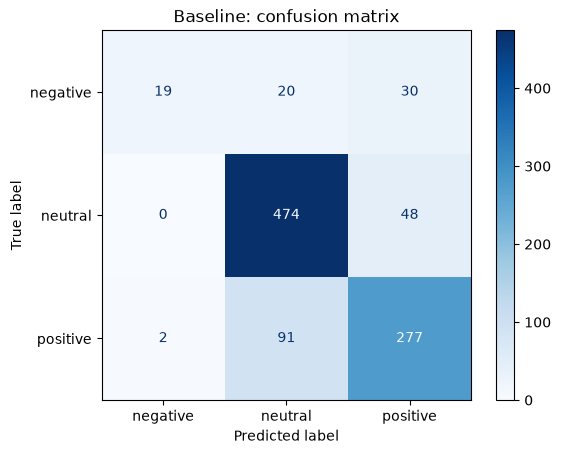

In [12]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=list(LABEL_NAMES.values()), cmap="Blues")
plt.title("Baseline: confusion matrix")
plt.show()

Сохраняю baseline как точку отсчёта

In [13]:
with open("../reports/baseline_result.txt", "w") as f:
    f.write(f"Baseline Macro F1: {baseline_f1:.4f}\n")
    f.write(f"Baseline Accuracy: {baseline_acc:.4f}\n")

baseline = {
    "model": "tfidf(5000, 1-2gram) + logreg",
    "test_macro_f1": round(baseline_f1, 4),
    "test_accuracy": round(baseline_acc, 4),
}
with open("../results/baseline_metrics.json", "w") as f:
    json.dump(baseline, f, indent=2)

joblib.dump({"model": model, "meta": baseline}, "../models/baseline.joblib")
baseline

{'model': 'tfidf(5000, 1-2gram) + logreg',
 'test_macro_f1': 0.6809,
 'test_accuracy': 0.8012}

Проверяю, что сохранённая модель работает на новых текстах

In [14]:
bundle = joblib.load("../models/baseline.joblib")
examples = [
    "operating profit rose 20 % compared to last year",
    "the company announced massive layoffs and its shares fell",
    "the meeting will be held in helsinki on monday",
]
for t, p in zip(examples, bundle["model"].predict(examples)):
    print(LABEL_NAMES[p], "<-", t)

positive <- operating profit rose 20 % compared to last year
neutral <- the company announced massive layoffs and its shares fell
neutral <- the meeting will be held in helsinki on monday


## Baseline

- модель: TF-IDF (5000 признаков, 1-2 граммы) + Logistic Regression, по README
- test macro F1: ..., accuracy: ...
- по классам: neutral F1 ..., positive F1 ..., negative F1 ...
- слабее всего negative: ...
- accuracy выше macro F1, потому что ...
- результат сохранён в reports/baseline_result.txt и results/baseline_metrics.json, модель в models/baseline.joblib
- цель дня 4: macro F1 не меньше ... (baseline * 1.05)